# House Price Prediction using Machine Learning

## How to open and run this notebook in Google Colab
1. Go to <https://colab.research.google.com> and sign in with a Google account.
2. Choose **File → Upload notebook** and select `House_Price_Prediction.ipynb` (or upload it to Google Drive and open it with Google Colab).
3. Click **Runtime → Run all** (or run each cell from top to bottom with `Shift + Enter`).
4. No API key, login or manual dataset download is needed. The dataset is loaded directly from a public URL. If that URL is unavailable, the notebook automatically falls back to the copy bundled with scikit-learn.
5. All the libraries used here (pandas, NumPy, Matplotlib, Seaborn, scikit-learn) are pre-installed in Colab.

**Note:** all numbers, tables and plots in this notebook are produced by the code cells when they run. Results are not typed in by hand.

## 1. Objective and Dataset
**Objective:** build and compare three regression models that predict the median house value of a California district (block group), then identify the best model using test-set performance.

**Dataset:** the *California Housing* dataset, derived from the 1990 U.S. Census (Pace & Barry, 1997). Each row describes one census block group, not one individual house. This notebook uses the CSV version popularised by Aurélien Géron's book *Hands-On Machine Learning* (it keeps the categorical column `ocean_proximity` and contains real missing values, which makes it a good exercise for cleaning and preprocessing). If that file cannot be downloaded, the notebook falls back to `sklearn.datasets.fetch_california_housing` (same census data, numeric features only).

**Target variable:** `median_house_value` (median house value of the block group, in US dollars).

**Features:** `longitude`, `latitude`, `housing_median_age`, `total_rooms`, `total_bedrooms`, `population`, `households`, `median_income` (in tens of thousands of dollars) and the categorical `ocean_proximity`.

The exact number of rows and columns is printed in Section 3.

## 2. Import Libraries

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")      # keep the output clean
sns.set_theme(style="whitegrid")       # consistent plot style
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42                      # fixed seed for reproducibility
print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the Dataset and Understand the Data

In [2]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
TARGET = "median_house_value"

try:
    df = pd.read_csv(DATA_URL)
    DATA_SOURCE = "CSV from the handson-ml2 GitHub repository"
except Exception as err:
    # Fallback: dataset bundled with scikit-learn (downloaded by scikit-learn itself)
    print("Primary download failed, using scikit-learn fallback:", err)
    from sklearn.datasets import fetch_california_housing
    raw = fetch_california_housing(as_frame=True).frame
    df = raw.rename(columns={"MedInc": "median_income", "HouseAge": "housing_median_age",
                             "Latitude": "latitude", "Longitude": "longitude"})
    df[TARGET] = raw["MedHouseVal"] * 100_000      # original unit is $100,000
    df = df.drop(columns="MedHouseVal")
    DATA_SOURCE = "sklearn.datasets.fetch_california_housing"

print("Data source:", DATA_SOURCE)
print("Shape (rows, columns):", df.shape)

Data source: CSV from the handson-ml2 GitHub repository
Shape (rows, columns): (20640, 10)


In [3]:
# First five rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
print("Column names:", list(df.columns))
print()
print("Data types:")
print(df.dtypes)
print()
df.info()

Column names: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Data types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 

In [5]:
# Descriptive statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [6]:
# Descriptive statistics for categorical columns (if any)
cat_cols_raw = df.select_dtypes(include="object").columns.tolist()
for c in cat_cols_raw:
    print(df[c].value_counts(), "\n")

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64 



### 3.1 Target distribution

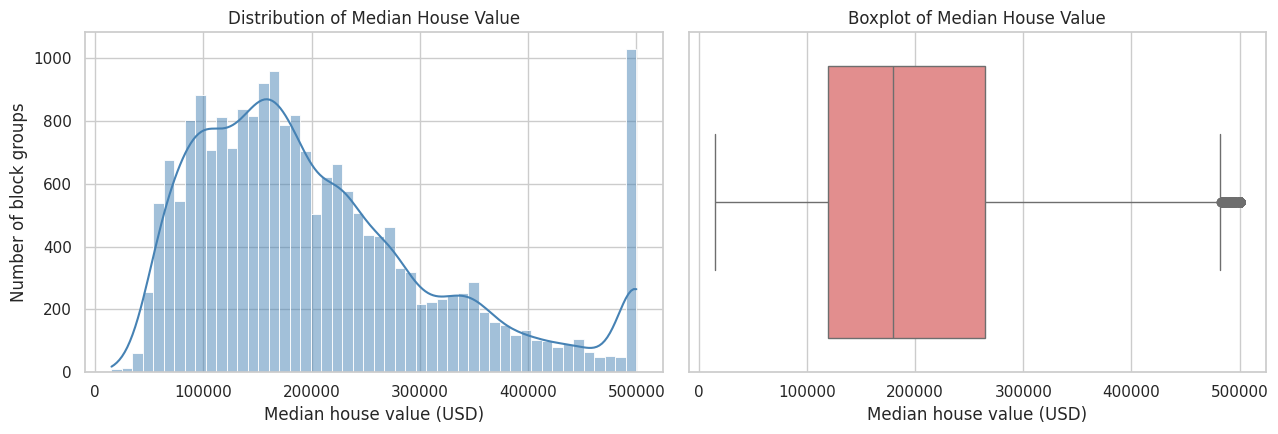

count     20640.00
mean     206855.82
std      115395.62
min       14999.00
25%      119600.00
50%      179700.00
75%      264725.00
max      500001.00
Name: median_house_value, dtype: float64
Skewness: 0.978
Rows at the maximum value: 965 | maximum = 500001.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df[TARGET], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Median House Value")
axes[0].set_xlabel("Median house value (USD)")
axes[0].set_ylabel("Number of block groups")
sns.boxplot(x=df[TARGET], ax=axes[1], color="lightcoral")
axes[1].set_title("Boxplot of Median House Value")
axes[1].set_xlabel("Median house value (USD)")
plt.tight_layout()
plt.show()

print(df[TARGET].describe().round(2))
print("Skewness:", round(df[TARGET].skew(), 3))
print("Rows at the maximum value:", int((df[TARGET] == df[TARGET].max()).sum()), "| maximum =", df[TARGET].max())

**Observations:** The house values are right-skewed (skewness ≈ 0.98): most block groups lie between about \$120,000 and \$265,000 (25th–75th percentile), with a long tail of expensive areas. There is also an artificial spike at the maximum value of \$500,001: 965 block groups share it, which means the values were capped when the data was collected. Models cannot learn what lies above this cap, which is a limitation of the dataset.

## 4. Data Cleaning
We check for missing values, duplicates, wrong data types, outliers and inconsistencies. Corrections are applied only when justified. Any step that *learns* a value from the data (such as the median used to fill missing values) is placed inside the modelling pipeline later, so it is learned from the **training set only** and does not leak information from the test set.

In [8]:
# 4.1 Missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_%": missing_pct})[missing > 0] if missing.sum() else print("No missing values.")

,missing_count,missing_%
total_bedrooms,207,1.0


In [9]:
# 4.2 Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
# 4.3 Data types: numeric columns should be numeric, text columns should be categories
print(df.dtypes)
print()
num_check = df.select_dtypes(include="number").columns.tolist()
print("Numeric columns:", num_check)
print("Text/categorical columns:", df.select_dtypes(exclude="number").columns.tolist())

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

Numeric columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
Text/categorical columns: ['ocean_proximity']


In [11]:
# 4.4 Outliers (IQR rule) - counted, NOT removed
num_cols_all = df.select_dtypes(include="number").columns
rows = []
for c in num_cols_all:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < low) | (df[c] > high)).sum())
    rows.append((c, n_out, round(n_out / len(df) * 100, 2)))
pd.DataFrame(rows, columns=["column", "outlier_count", "outlier_%"]).set_index("column")

,outlier_count,outlier_%
column,,
longitude,0,0.00
latitude,0,0.00
housing_median_age,0,0.00
total_rooms,1287,6.24
total_bedrooms,1271,6.16
population,1196,5.79
households,1220,5.91
median_income,681,3.30
median_house_value,1071,5.19


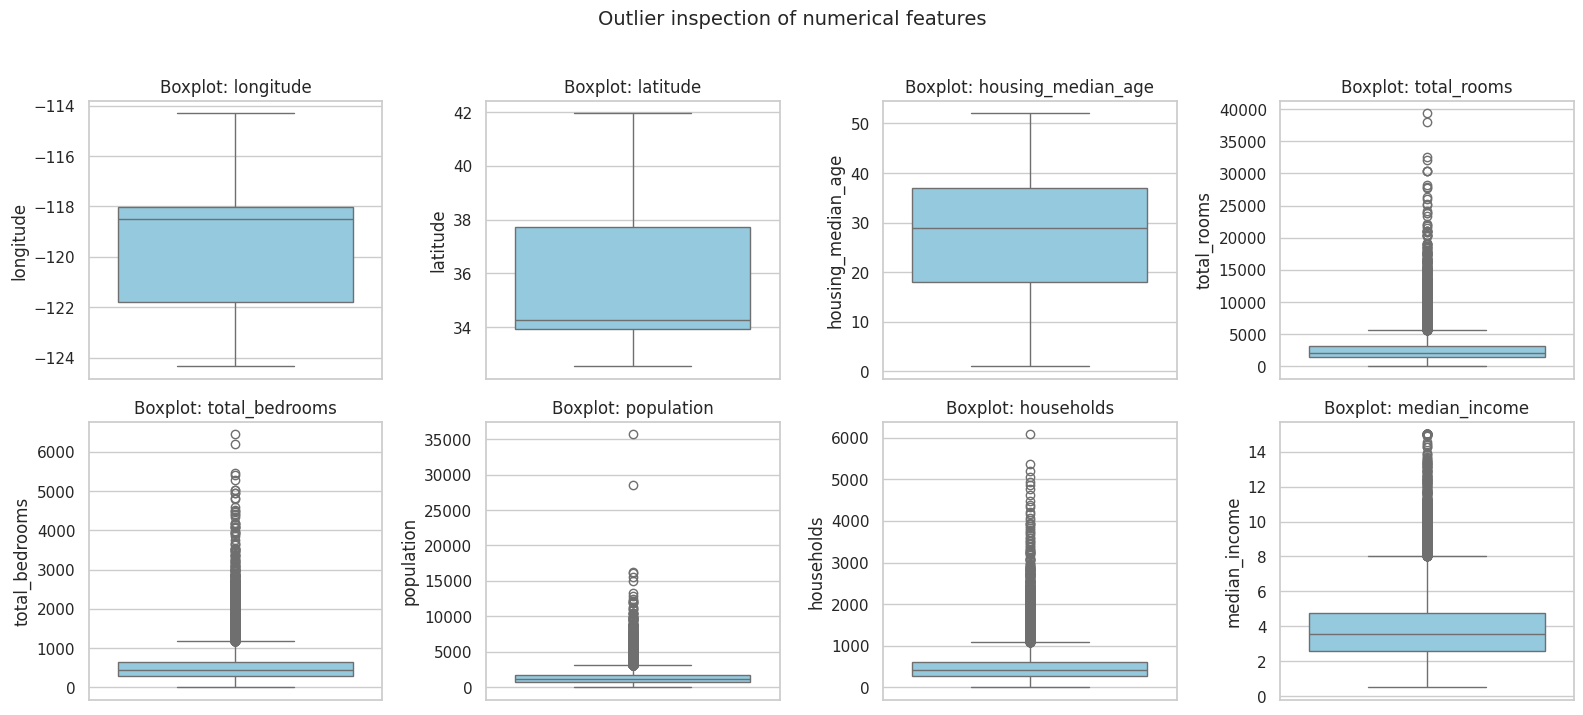

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), [c for c in num_cols_all if c != TARGET][:8]):
    sns.boxplot(y=df[c], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot: {c}")
plt.suptitle("Outlier inspection of numerical features", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
# 4.5 Inconsistencies: impossible values and capped values
print("Columns with zero or negative values that should be positive:")
for c in ["total_rooms", "total_bedrooms", "population", "households", "median_income", "housing_median_age"]:
    if c in df:
        print(f"  {c}: {(df[c] <= 0).sum()} rows <= 0")
if "total_bedrooms" in df and "total_rooms" in df:
    print("\nRows with more bedrooms than rooms:", int((df["total_bedrooms"] > df["total_rooms"]).sum()))
print("\nHighest values of key columns (look for artificial caps):")
for c in [TARGET, "housing_median_age"]:
    top = df[c].max()
    print(f"  {c}: max = {top}, rows at max = {int((df[c] == top).sum())}")

Columns with zero or negative values that should be positive:
  total_rooms: 0 rows <= 0
  total_bedrooms: 0 rows <= 0
  population: 0 rows <= 0
  households: 0 rows <= 0
  median_income: 0 rows <= 0
  housing_median_age: 0 rows <= 0

Rows with more bedrooms than rooms: 0

Highest values of key columns (look for artificial caps):
  median_house_value: max = 500001.0, rows at max = 965
  housing_median_age: max = 52.0, rows at max = 1273


**Cleaning decisions:**
- **Missing values:** only `total_bedrooms` has missing values (207 rows, 1.0 %). Dropping them would waste valid data, so they are imputed with the training-set median inside the pipeline (no leakage).
- **Duplicates:** 0 duplicate rows were found, so nothing was removed.
- **Data types:** all numerical columns are numeric (`float64`) and `ocean_proximity` is a text category, so no type conversion is needed. The category is one-hot encoded in the pipeline.
- **Outliers:** the IQR rule flags roughly 3–6 % of rows in `total_rooms`, `total_bedrooms`, `population`, `households`, `median_income` and the target. These are very large block groups or very wealthy/expensive areas that are real observations, so they are **kept**.
- **Inconsistencies:** no zero or negative counts and no block group with more bedrooms than rooms. However, `median_house_value` is capped at \$500,001 (965 rows) and `housing_median_age` is capped at 52 years (1,273 rows). These caps are not corrected because the true values are unknown; they are noted as a limitation.

## 5. Exploratory Data Analysis (EDA)

### 5.1 Distributions of the numerical features

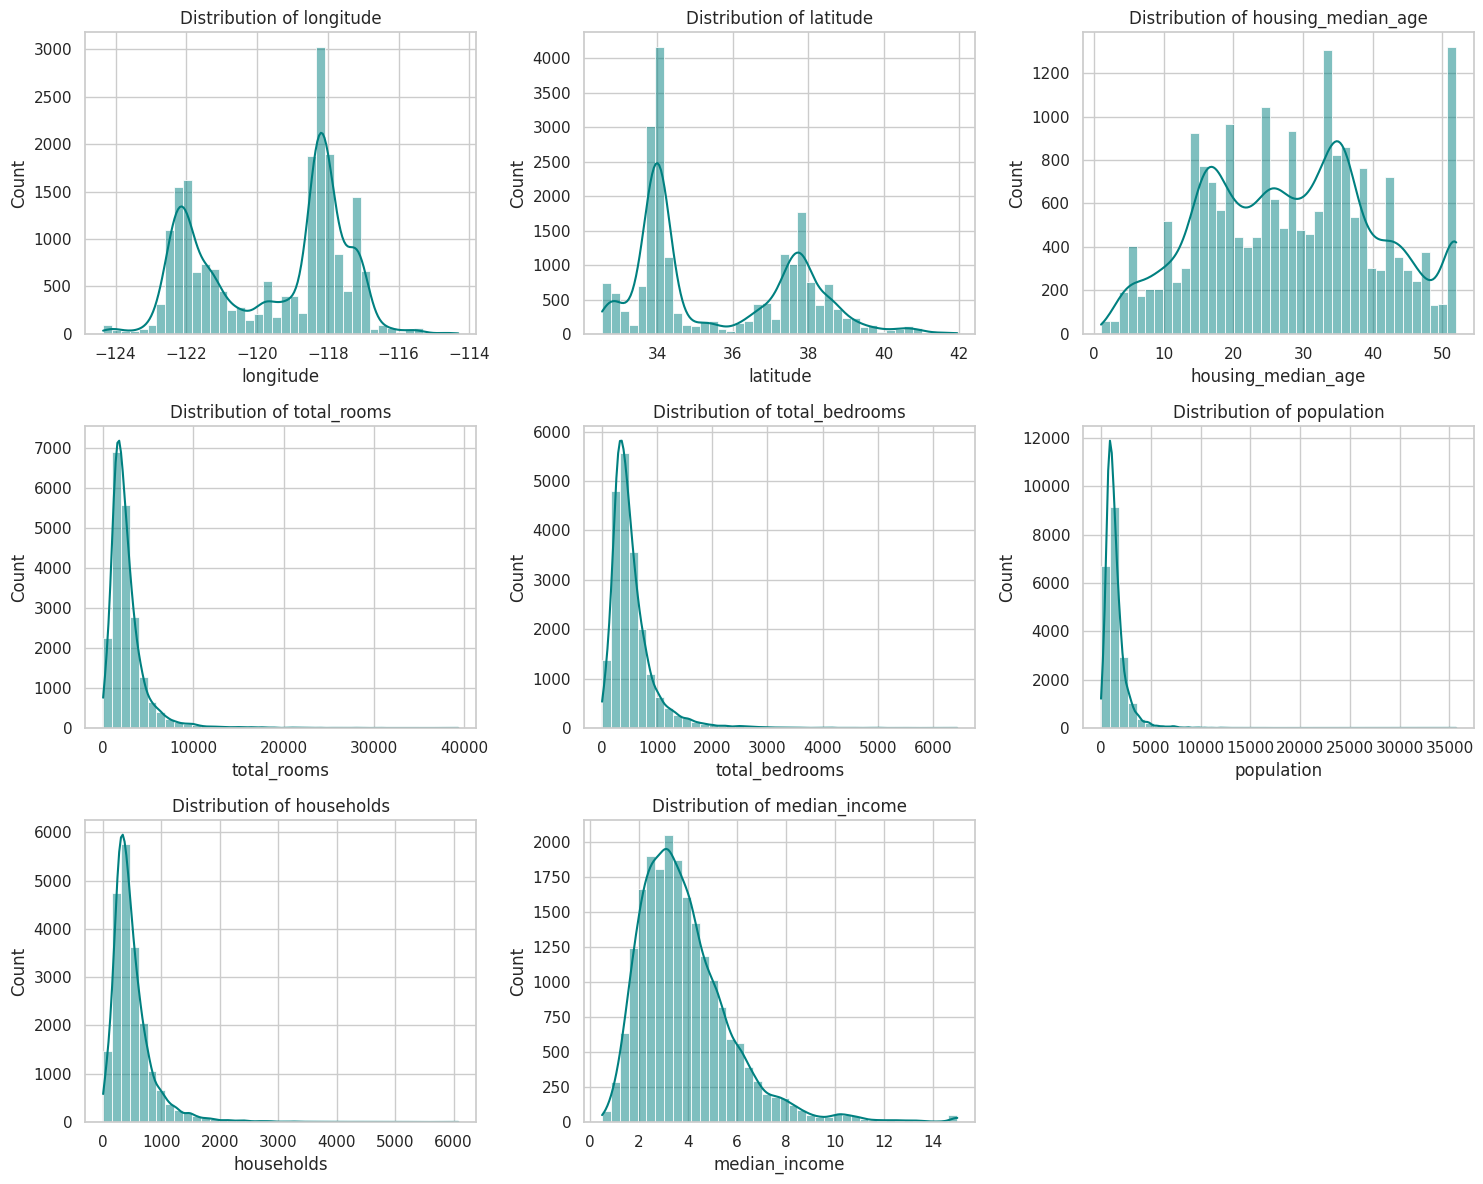

In [14]:
num_features_eda = [c for c in df.select_dtypes(include="number").columns if c != TARGET]
n = len(num_features_eda)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
for ax, c in zip(axes.ravel(), num_features_eda):
    sns.histplot(df[c], bins=40, kde=True, ax=ax, color="teal")
    ax.set_title(f"Distribution of {c}")
    ax.set_xlabel(c)
    ax.set_ylabel("Count")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observations:** `total_rooms`, `total_bedrooms`, `population` and `households` are strongly right-skewed (skewness between about 3.4 and 4.9): most block groups are small, while a few are very large. `median_income` is also moderately right-skewed (≈ 1.65). `housing_median_age` shows a pile-up at its cap of 52 years. Longitude and latitude show clusters, reflecting the concentration of the population in a few regions of California. Because of the skew, scaling is applied for Linear Regression, and tree-based models are not affected by it.

### 5.2 Correlation heatmap

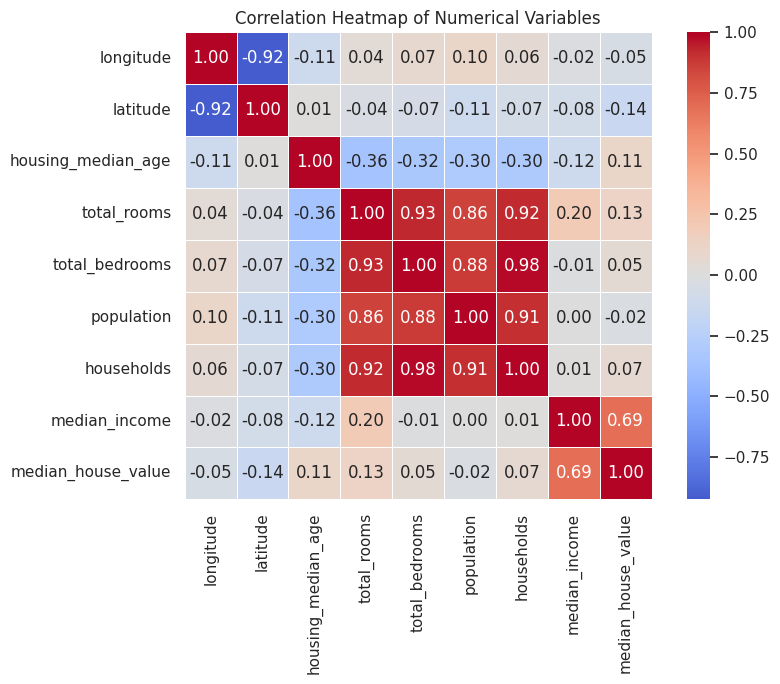

Correlation of each feature with the target:
median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64


In [15]:
plt.figure(figsize=(9, 7))
corr = df.select_dtypes(include="number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

print("Correlation of each feature with the target:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

**Observations:** `median_income` has by far the strongest positive correlation with house value (≈ 0.69). All other features have weak linear correlations with the target (absolute values below about 0.15). `total_rooms`, `total_bedrooms`, `population` and `households` are highly correlated with each other (0.86–0.98), which indicates multicollinearity: they mostly measure the size of the block group. `longitude` and `latitude` are also strongly (negatively) correlated (≈ −0.92) because California's coast runs diagonally. Multicollinearity can make Linear Regression coefficients unstable but does not stop the models from predicting.

### 5.3 Relationships between features and house value

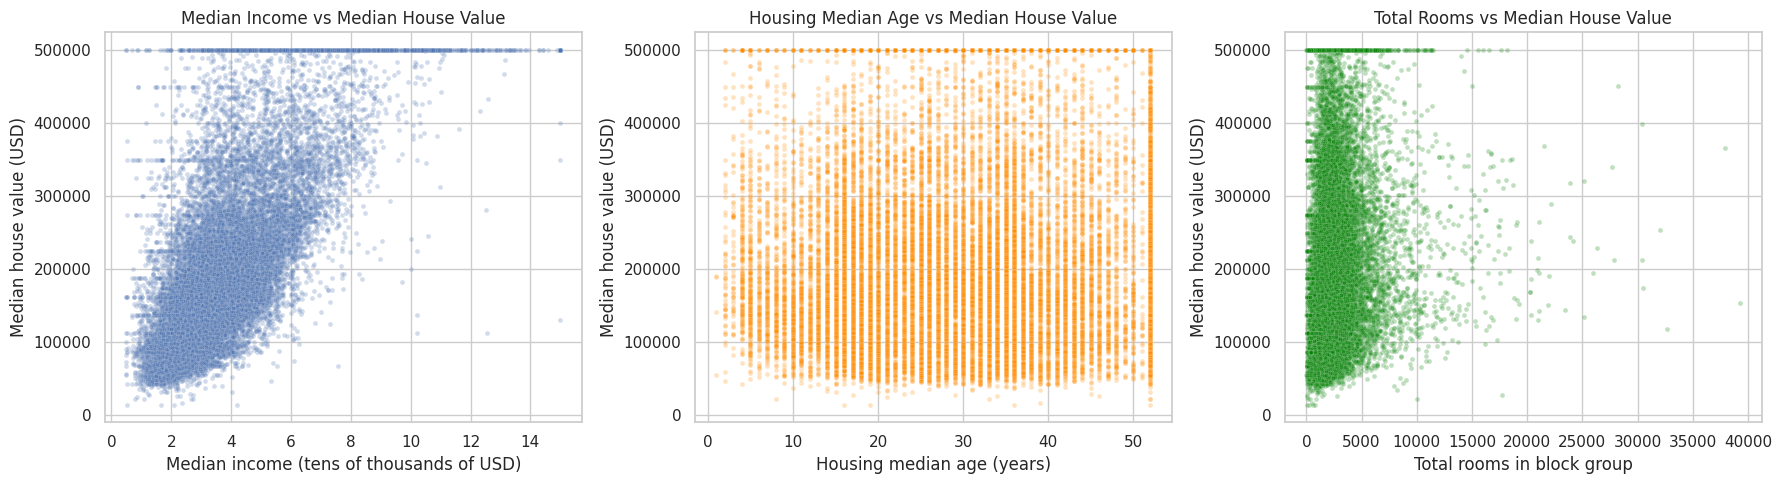

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x="median_income", y=TARGET, alpha=0.25, s=12, ax=axes[0])
axes[0].set_title("Median Income vs Median House Value")
axes[0].set_xlabel("Median income (tens of thousands of USD)")
axes[0].set_ylabel("Median house value (USD)")

sns.scatterplot(data=df, x="housing_median_age", y=TARGET, alpha=0.25, s=12, ax=axes[1], color="darkorange")
axes[1].set_title("Housing Median Age vs Median House Value")
axes[1].set_xlabel("Housing median age (years)")
axes[1].set_ylabel("Median house value (USD)")

if "total_rooms" in df:
    sns.scatterplot(data=df, x="total_rooms", y=TARGET, alpha=0.25, s=12, ax=axes[2], color="green")
    axes[2].set_title("Total Rooms vs Median House Value")
    axes[2].set_xlabel("Total rooms in block group")
else:
    sns.scatterplot(data=df, x="population", y=TARGET, alpha=0.25, s=12, ax=axes[2], color="green")
    axes[2].set_title("Population vs Median House Value")
axes[2].set_ylabel("Median house value (USD)")
plt.tight_layout()
plt.show()

**Observations:** house value rises with `median_income`, which matches the high correlation. The horizontal band of points at \$500,001 is the price cap discussed earlier. The relationship with `housing_median_age` and `total_rooms` is much weaker, which agrees with their low correlation values.

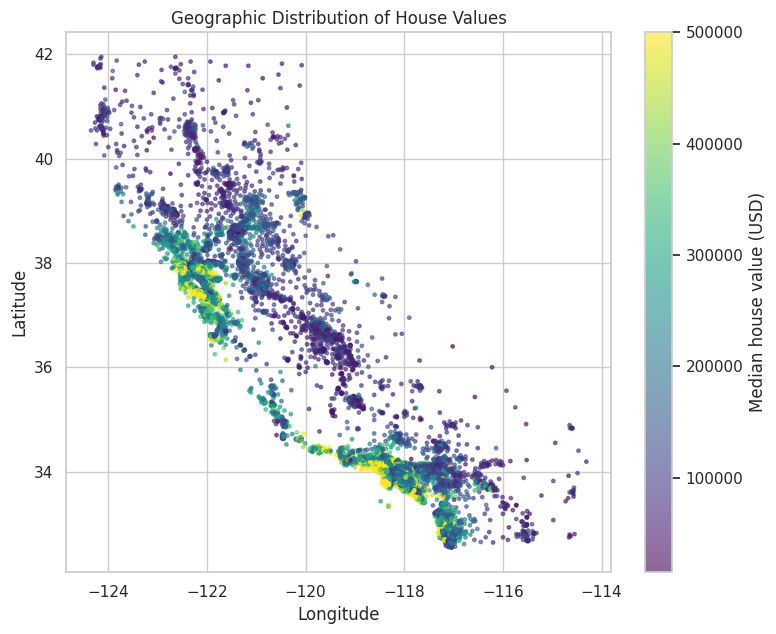

In [17]:
# Geographic view: location and price
plt.figure(figsize=(8, 6.5))
sc = plt.scatter(df["longitude"], df["latitude"], c=df[TARGET], cmap="viridis", s=6, alpha=0.6)
plt.colorbar(sc, label="Median house value (USD)")
plt.title("Geographic Distribution of House Values")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

**Observations:** location clearly matters. The most expensive block groups (yellow) cluster along the coast, especially around the San Francisco Bay Area and the Los Angeles / San Diego coastline, while inland areas (central valley, north and east) are mostly in the lower price range. Tree-based models can split the map into such regions, whereas a linear model on raw longitude/latitude can use this information only in a limited way.

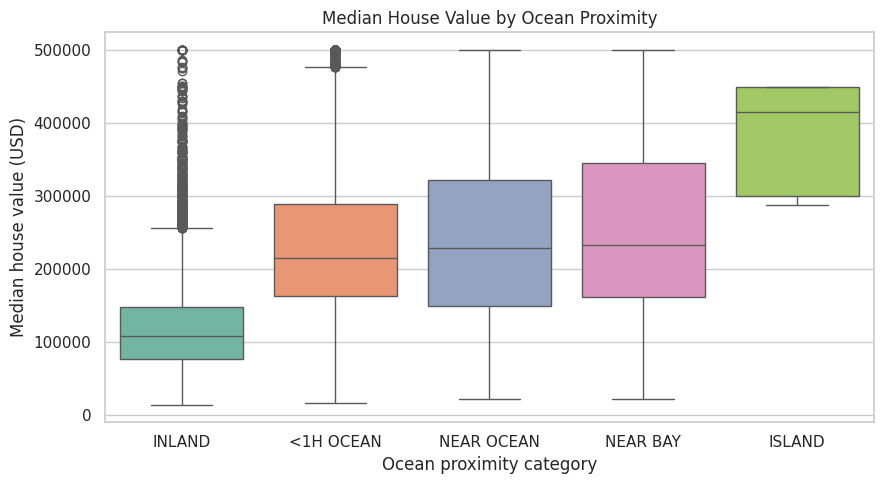

                 count    median      mean
ocean_proximity                           
<1H OCEAN         9136  214850.0  240084.0
INLAND            6551  108500.0  124805.0
ISLAND               5  414700.0  380440.0
NEAR BAY          2290  233800.0  259212.0
NEAR OCEAN        2658  229450.0  249434.0


In [18]:
# Categorical feature vs price (only when ocean_proximity is available)
if "ocean_proximity" in df:
    order = df.groupby("ocean_proximity")[TARGET].median().sort_values().index
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df, x="ocean_proximity", y=TARGET, order=order, palette="Set2")
    plt.title("Median House Value by Ocean Proximity")
    plt.xlabel("Ocean proximity category")
    plt.ylabel("Median house value (USD)")
    plt.tight_layout()
    plt.show()
    print(df.groupby("ocean_proximity")[TARGET].agg(["count", "median", "mean"]).round(0))
else:
    print("ocean_proximity is not available in the fallback dataset.")

**Observations:** `INLAND` block groups have a much lower median house value (≈ \$108,500) than the other categories (≈ \$215,000–\$234,000 for `<1H OCEAN`, `NEAR OCEAN` and `NEAR BAY`). `ISLAND` has only 5 rows, so its statistics are not reliable. The category is therefore a useful predictor.

## 6. Preprocessing (without data leakage)
Steps:
1. Separate the features `X` from the target `y`.
2. Split into **80 % training / 20 % testing** with `random_state=42`. The split happens **before** any imputation or scaling.
3. Build a `ColumnTransformer`:
   - numerical columns → median imputation (`SimpleImputer`) + `StandardScaler`
   - categorical columns → most-frequent imputation + `OneHotEncoder(handle_unknown="ignore")`
4. Put the preprocessor and each model into a `Pipeline`. When `fit` is called, the imputer, scaler and encoder learn their values from the training data only, and the same learned values are then applied to the test data.

Outliers are kept: they are valid observations, and tree-based models are not sensitive to them. The median (not the mean) is used for imputation because several features are strongly skewed.

In [19]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("\nNumeric features    :", numeric_features)
print("Categorical features:", categorical_features)

X_train: (16512, 9) | X_test: (4128, 9)
y_train: (16512,) | y_test: (4128,)

Numeric features    : ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']


In [20]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

transformers = [("num", numeric_pipe, numeric_features)]
if categorical_features:
    transformers.append(("cat", categorical_pipe, categorical_features))
preprocessor = ColumnTransformer(transformers)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## 7. Train the Regression Models
All models use the **same** training/testing split and the **same** preprocessing:
- **Linear Regression** – a simple baseline that fits a straight-line (linear) relationship.
- **Decision Tree Regressor** – splits the data into regions using if/else rules; can capture non-linear patterns but easily overfits when unrestricted.
- **Random Forest Regressor** – an average of many decision trees trained on random subsets; usually more accurate and stable than a single tree.

In [21]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
}

fitted = {}
for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)          # preprocessing is learned from X_train only
    fitted[name] = pipe
    print(f"Trained: {name}")

Trained: Linear Regression


Trained: Decision Tree


Trained: Random Forest


## 8. Model Evaluation
| Metric | Meaning | Better is |
|---|---|---|
| **MAE** (Mean Absolute Error) | Average size of the prediction error, in dollars | lower |
| **MSE** (Mean Squared Error) | Average of squared errors; punishes large errors heavily; unit is dollars² | lower |
| **RMSE** (Root Mean Squared Error) | Square root of MSE, back in dollars; sensitive to large errors | lower |
| **R²** (R-squared) | Share of the variance in house prices explained by the model (1 = perfect, 0 = no better than predicting the mean) | higher |

We also report the training R² to detect overfitting (a large gap between training R² and test R² is a warning sign).

In [22]:
def evaluate(name, pipe):
    pred_test = pipe.predict(X_test)
    pred_train = pipe.predict(X_train)
    mse = mean_squared_error(y_test, pred_test)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred_test),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 (test)": r2_score(y_test, pred_test),
        "R2 (train)": r2_score(y_train, pred_train),
    }

results = pd.DataFrame([evaluate(n, p) for n, p in fitted.items()]).set_index("Model")
results.style.format({"MAE": "{:,.0f}", "MSE": "{:,.0f}", "RMSE": "{:,.0f}",
                      "R2 (test)": "{:.4f}", "R2 (train)": "{:.4f}"}) \
       .highlight_min(subset=["MAE", "MSE", "RMSE"], color="#c6efce") \
       .highlight_max(subset=["R2 (test)"], color="#c6efce")

,MAE,MSE,RMSE,R2 (test),R2 (train)
Model,,,,,
Linear Regression,"50,670","4,908,290,571","70,059",0.6254,0.6497
Decision Tree,"43,604","4,785,287,043","69,176",0.6348,1.0000
Random Forest,"31,628","2,395,290,032","48,942",0.8172,0.9756


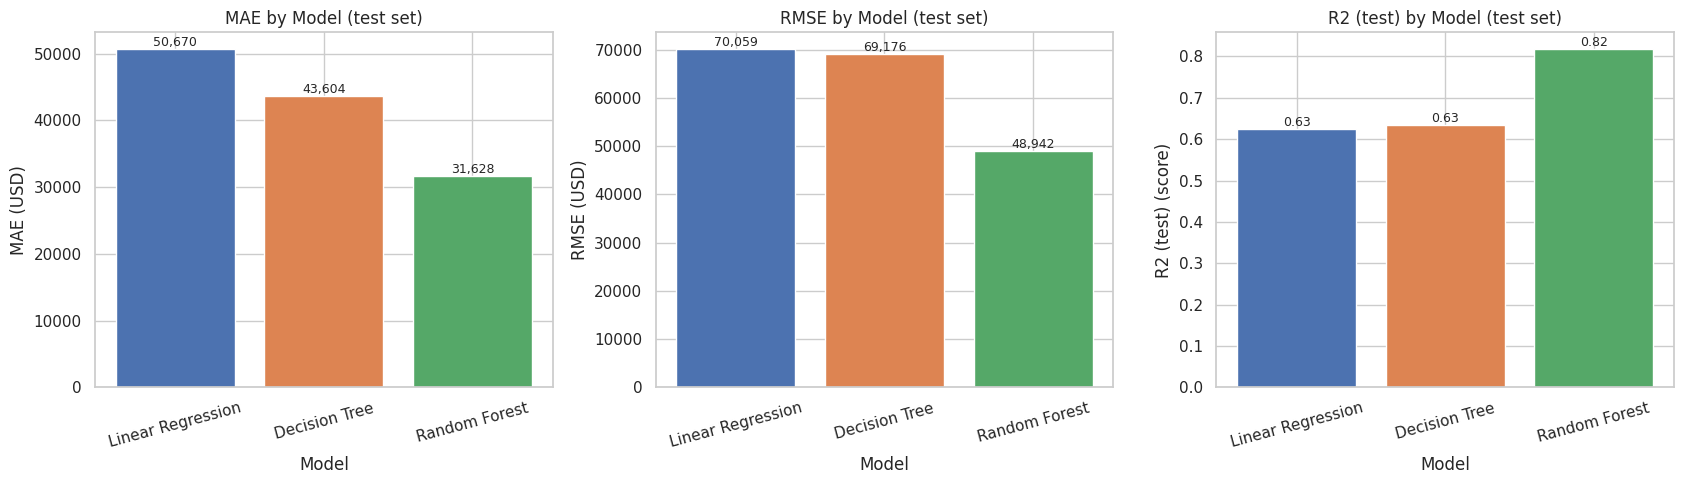

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
palette = ["#4c72b0", "#dd8452", "#55a868"]
for ax, metric, unit in zip(axes, ["MAE", "RMSE", "R2 (test)"], ["USD", "USD", "score"]):
    bars = ax.bar(results.index, results[metric], color=palette)
    ax.set_title(f"{metric} by Model (test set)")
    ax.set_ylabel(f"{metric} ({unit})")
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=15)
    for b, v in zip(bars, results[metric]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:,.2f}" if metric == "R2 (test)" else f"{v:,.0f}",
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

In [24]:
# Pick the best model from the actual results: lowest RMSE, then check R2 agrees
best_by_rmse = results["RMSE"].idxmin()
best_by_r2 = results["R2 (test)"].idxmax()
best_name = best_by_rmse
print("Lowest RMSE :", best_by_rmse)
print("Highest R2  :", best_by_r2)
print("Both criteria agree." if best_by_rmse == best_by_r2 else "Criteria disagree - inspect the table.")
print("\nSelected best model:", best_name)

Lowest RMSE : Random Forest
Highest R2  : Random Forest
Both criteria agree.

Selected best model: Random Forest


**Observations (based on the table and charts above):**
- **Random Forest** has the lowest MAE (≈ \$31,600), MSE and RMSE (≈ \$48,900) and the highest test R² (≈ 0.817), so it is the best model on every metric.
- **Linear Regression** (RMSE ≈ \$70,100, R² ≈ 0.625) and the **Decision Tree** (RMSE ≈ \$69,200, R² ≈ 0.635) perform similarly in RMSE and R². The Decision Tree has the lower MAE (≈ \$43,600 vs ≈ \$50,700).
- The unrestricted Decision Tree has a training R² of 1.0 but a test R² of only about 0.63, a clear sign of **overfitting**: it memorised the training data. The Random Forest also shows a gap (train R² ≈ 0.976 vs test R² ≈ 0.817) but generalises much better because averaging many trees reduces variance.
- Linear Regression has similar train (≈ 0.650) and test (≈ 0.625) R², so it is not overfitting; it underfits because house prices depend on non-linear effects such as location.
- With the fixed `random_state=42` split, these values are reproducible. Results from one split are an estimate; different splits would give slightly different numbers.

## 9. Analysis of the Best Model

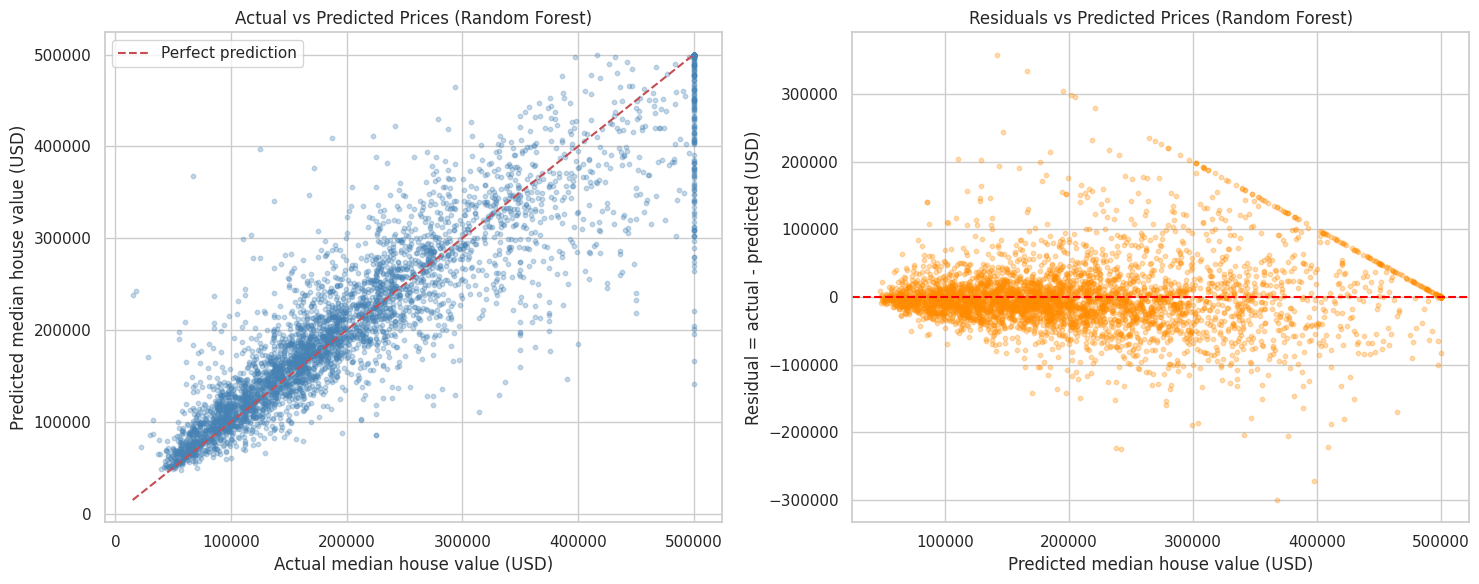

In [25]:
best_pipe = fitted[best_name]
y_pred = best_pipe.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(y_test, y_pred, alpha=0.3, s=10, color="steelblue")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_title(f"Actual vs Predicted Prices ({best_name})")
axes[0].set_xlabel("Actual median house value (USD)")
axes[0].set_ylabel("Predicted median house value (USD)")
axes[0].legend()

axes[1].scatter(y_pred, residuals, alpha=0.3, s=10, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title(f"Residuals vs Predicted Prices ({best_name})")
axes[1].set_xlabel("Predicted median house value (USD)")
axes[1].set_ylabel("Residual = actual - predicted (USD)")
plt.tight_layout()
plt.show()

**Observations:** the Random Forest predictions follow the red dashed diagonal, so it tracks actual prices reasonably well overall. The vertical column of points at an actual value of \$500,001 is the price cap: those areas are predicted anywhere from roughly \$150,000 to \$500,000, so many are under-predicted. In the residual plot this cap creates the straight diagonal line of points on the right side. The spread of the residuals is also wider for higher predicted prices than for lower ones, so the error size is not constant (heteroscedasticity).

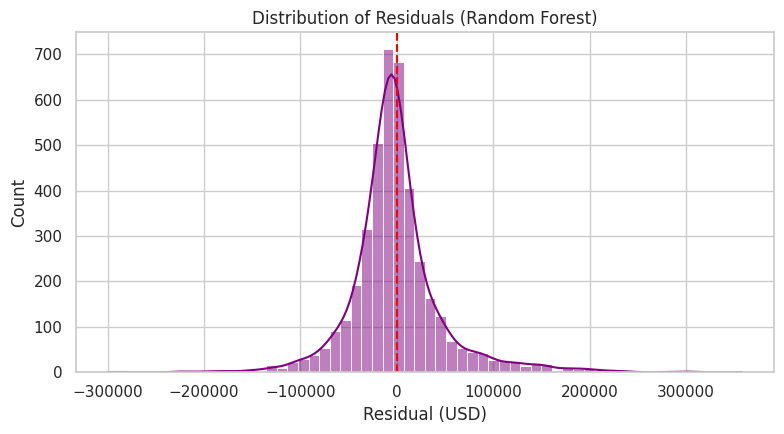

Mean residual: -843.93 USD | Std of residuals: 48940.35 USD


In [26]:
plt.figure(figsize=(8, 4.5))
sns.histplot(residuals, bins=60, kde=True, color="purple")
plt.axvline(0, color="red", linestyle="--")
plt.title(f"Distribution of Residuals ({best_name})")
plt.xlabel("Residual (USD)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
print("Mean residual:", round(residuals.mean(), 2), "USD | Std of residuals:", round(residuals.std(), 2), "USD")

**Observations:** the residuals form a peak close to zero, and the mean residual (≈ −\$844) shows little overall bias. Their standard deviation is about \$48,900, which matches the RMSE. The tails are fairly long, with a slightly heavier right tail (actual price higher than predicted), meaning that a few block groups have large errors, many of them linked to the capped \$500,001 values.

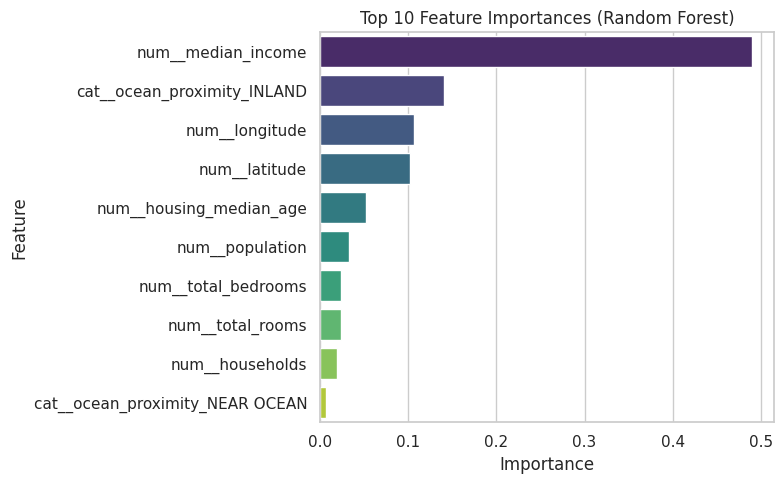

In [27]:
# Feature importance (only for tree-based best models)
final_model = best_pipe.named_steps["model"]
if hasattr(final_model, "feature_importances_"):
    feat_names = best_pipe.named_steps["preprocess"].get_feature_names_out()
    imp = pd.Series(final_model.feature_importances_, index=feat_names).sort_values(ascending=False).head(10)
    plt.figure(figsize=(8, 5))
    sns.barplot(x=imp.values, y=imp.index, palette="viridis")
    plt.title(f"Top 10 Feature Importances ({best_name})")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importances are not available for this model type.")

**Observations:** `median_income` is the most important feature (≈ 49 % of total importance), followed by the `INLAND` category (≈ 14 %), `longitude` (≈ 11 %) and `latitude` (≈ 10 %). This agrees with the EDA: income and location are the main drivers of house value in this dataset.

**Limitations and overfitting:** the Random Forest still fits the training data much better (R² ≈ 0.976) than the test data (R² ≈ 0.817). Hyperparameter tuning (for example limiting `max_depth` or using cross-validation) could reduce this gap but was outside the scope of this assignment. Other limitations: the data comes from 1990, each row is a block group rather than a single house, house values are capped at \$500,001, and only one train/test split was used.

## 10. Predict the Price of a Sample House

The model predicts the **median house value of a block group** (an area with many households) in **US dollars (1990 census values)**, based on the features below. Units: `longitude`/`latitude` in degrees, `housing_median_age` in years, `total_rooms`/`total_bedrooms`/`population`/`households` are counts for the whole block group, and `median_income` is in tens of thousands of USD. Predictions only make sense for inputs similar to California in the dataset and within the feature ranges seen in training.

In [28]:
sample = {
    "longitude": -122.25, "latitude": 37.85,
    "housing_median_age": 30.0,
    "total_rooms": 2500.0, "total_bedrooms": 500.0,
    "population": 1200.0, "households": 450.0,
    "median_income": 5.0,                    # = about $50,000
    "ocean_proximity": "NEAR BAY",
}
if set(sample) == set(X.columns):
    sample_df = pd.DataFrame([sample])[X.columns]
else:                                         # fallback dataset has different columns
    sample_df = X_test.iloc[[0]]
    print("Using the first test row as the sample (fallback dataset columns).")

display(sample_df)
predicted_price = best_pipe.predict(sample_df)[0]
print(f"Model used: {best_name}")
print(f"Predicted median house value: ${predicted_price:,.0f}")

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.25,37.85,30.0,2500.0,500.0,1200.0,450.0,5.0,NEAR BAY


Model used: Random Forest
Predicted median house value: $273,356


## 11. Conclusion

This project loaded the California Housing dataset (20,640 block groups, 9 features and the target `median_house_value`), cleaned it (207 missing `total_bedrooms` values imputed with the training median; no duplicates; outliers kept; value caps noted), explored it with several plots, and trained three regression models in leakage-free pipelines on one fixed 80/20 split.

On the test set, **Random Forest was the best model** (MAE ≈ \$31,600, RMSE ≈ \$48,900, R² ≈ 0.817), clearly ahead of the Decision Tree (RMSE ≈ \$69,200, R² ≈ 0.635) and Linear Regression (RMSE ≈ \$70,100, R² ≈ 0.625). Median income and location were the most influential features.

**Limitations:** data from 1990 at block-group level, capped values at \$500,001 and capped house age, no hyperparameter tuning or cross-validation, and the Random Forest still overfits somewhat. Predictions are only meaningful for inputs similar to the dataset's California census areas.

## 12. References
- California Housing dataset, scikit-learn documentation: <https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html>
- Pace, R. K. and Barry, R. (1997). *Sparse Spatial Autoregressions*. Statistics & Probability Letters, 33, 291–297 (original source of the data).
- CSV copy used in this notebook (Géron, *Hands-On Machine Learning*): <https://github.com/ageron/handson-ml2/tree/master/datasets/housing>
- scikit-learn `ColumnTransformer`: <https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html>
- scikit-learn `Pipeline`: <https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html>
- scikit-learn regression metrics: <https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics>
- `LinearRegression`: <https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html>
- `DecisionTreeRegressor`: <https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html>
- `RandomForestRegressor`: <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html>
- pandas: <https://pandas.pydata.org/docs/> · Matplotlib: <https://matplotlib.org/stable/> · Seaborn: <https://seaborn.pydata.org/>